## MVA - "Méthodes de séparation de sources pour l’analyse de données en astrophysique"

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from scripts.palm import PALM

# Retrieving the data

In [3]:
chandra_pickle = np.load("./data/chandra_data.npy", allow_pickle=True).item()

X_linear_model = chandra_pickle['LinModel']
A_linear_model = chandra_pickle['MixingMatrix']
S_all_models = chandra_pickle['Sources']
X_complex_model = chandra_pickle['ComplexSims']
X_real_data = chandra_pickle['RealData']

print("X_linear_model:", X_linear_model.shape)
print("A_linear_model:", A_linear_model.shape)
print("S_all_models:", S_all_models.shape)
print("X_complex_model:", X_complex_model.shape)
print("X_real_data:", X_real_data.shape)

X_linear_model: (40, 128, 128)
A_linear_model: (40, 3)
S_all_models: (3, 128, 128)
X_complex_model: (40, 230, 230)
X_real_data: (40, 256, 256)


In [4]:
A_est,S_est,it = PALM(X_linear_model.reshape(40,-1),A_linear_model,S_all_models.reshape(3,-1),lamb=1e-2,itmax=100)

itmax 100


In [5]:
for A,X,S in [(A_linear_model,X_linear_model,S_all_models)]:
    print(X.shape)
    print(X.size)

(40, 128, 128)
655360


## real source 

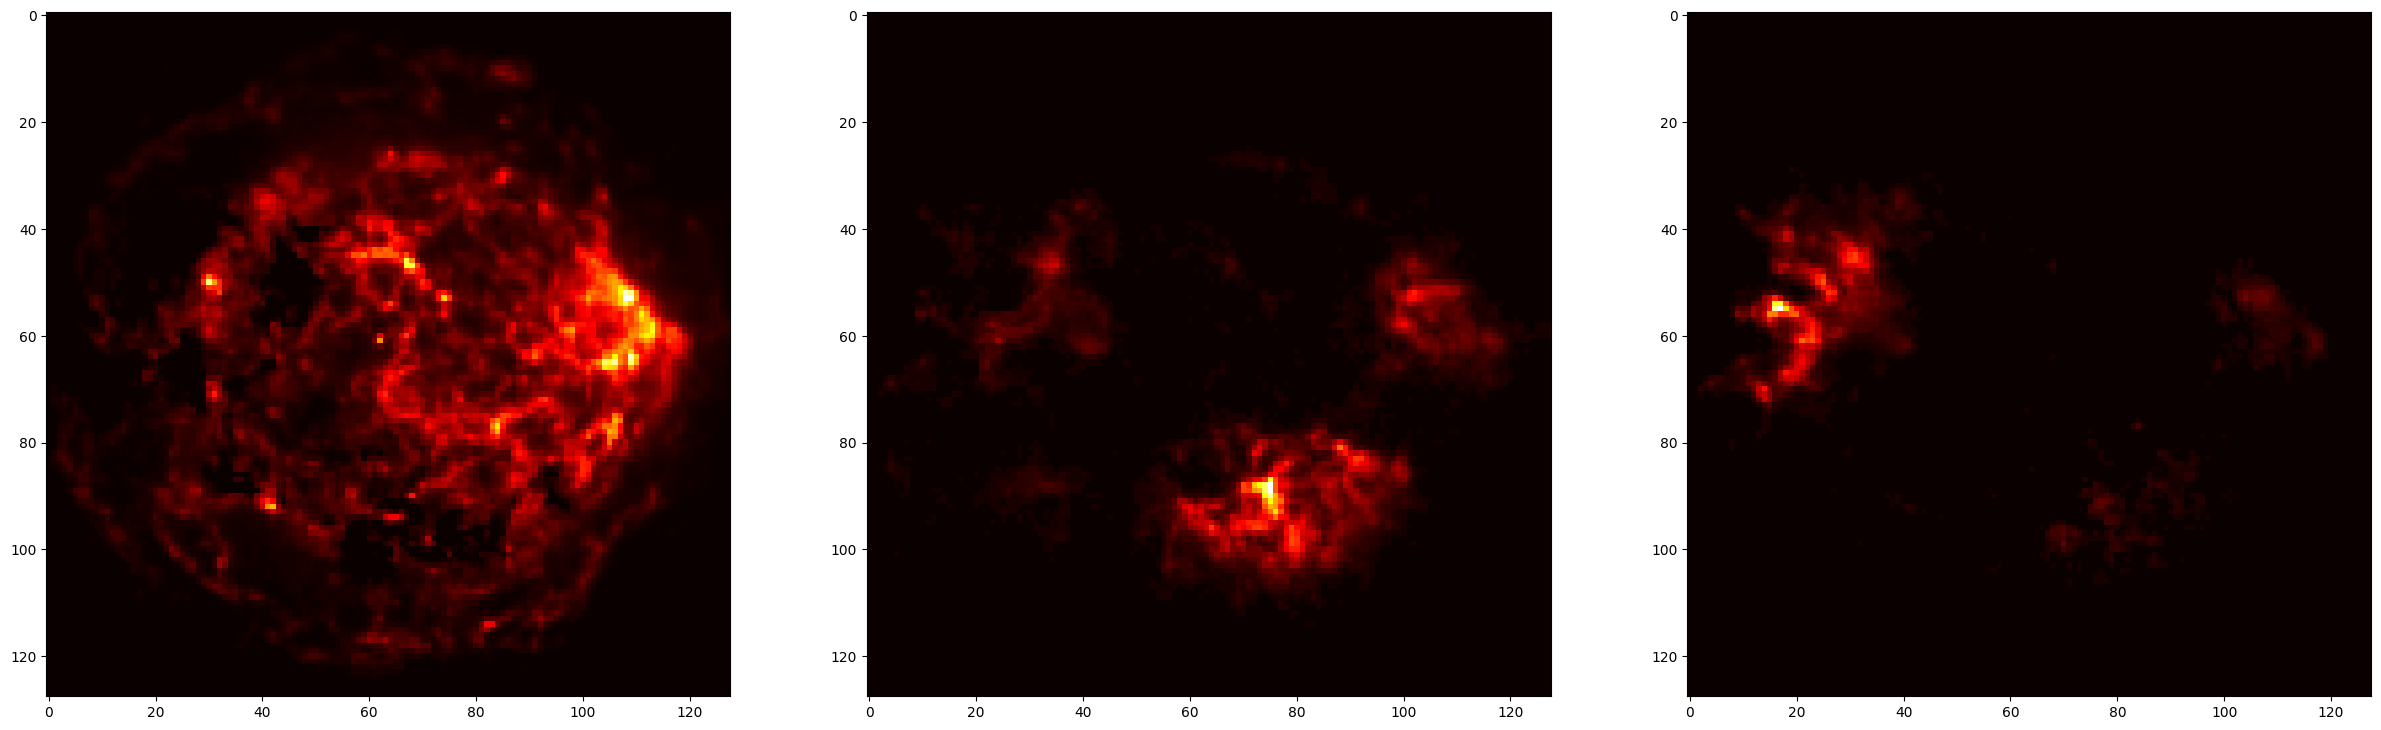

In [6]:
f,ax = plt.subplots(1,3,figsize=(30,15))
for k in range(3):
    ax[k].imshow(S[k],#.transpose(1,2,0),
              cmap='hot')
plt.show()

## Estimated source through Palm 

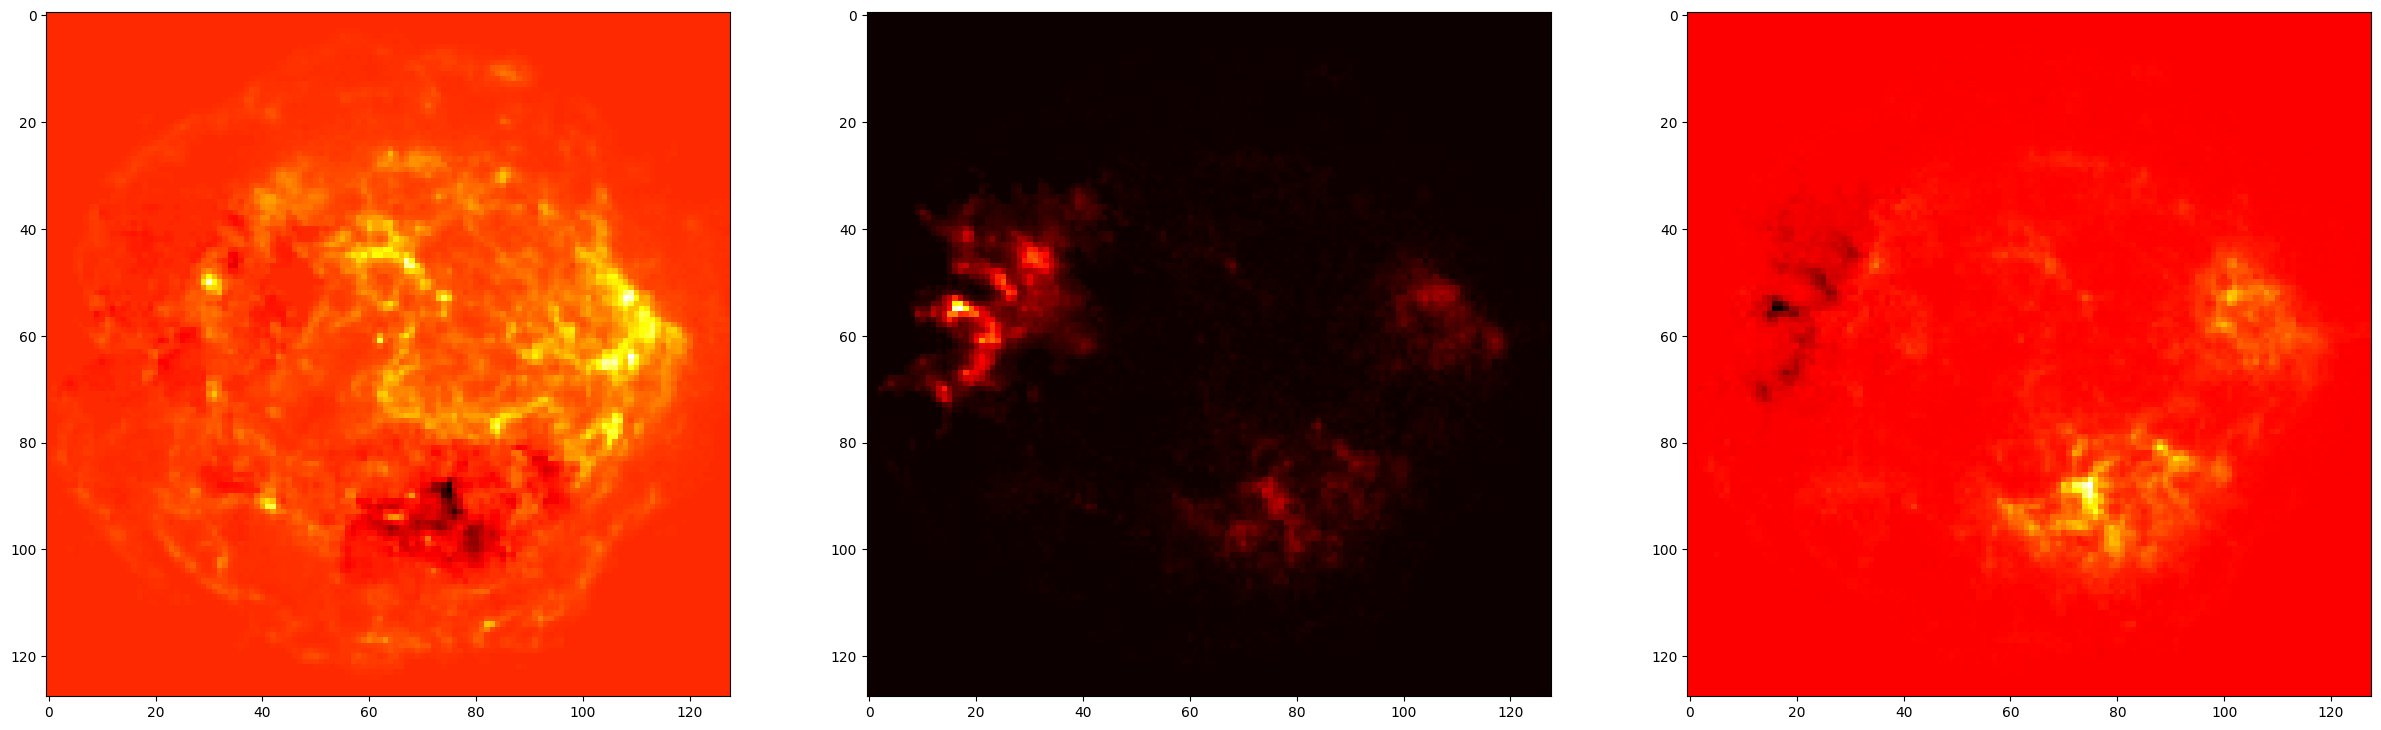

In [7]:
f,ax = plt.subplots(1,3,figsize=(30,15))
for k in range(3):
    ax[k].imshow(S_est[k].reshape(128,128),#.transpose(1,2,0),
              cmap='hot')
plt.show()

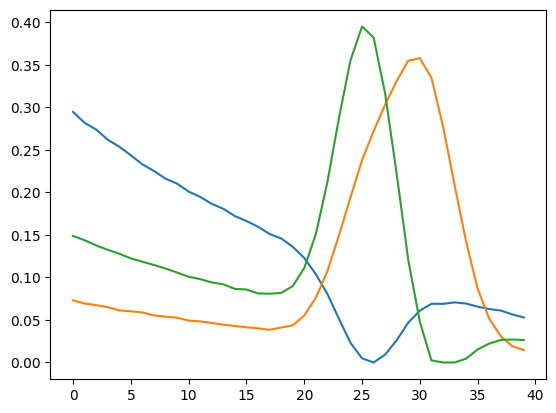

In [8]:
plt.plot(A_est)

In [9]:
from scripts.ista import ISTA_S

In [10]:
S_est,it = ISTA_S(X_linear_model.reshape(40,-1),A_linear_model,S_all_models.reshape(3,-1),lamb=1)

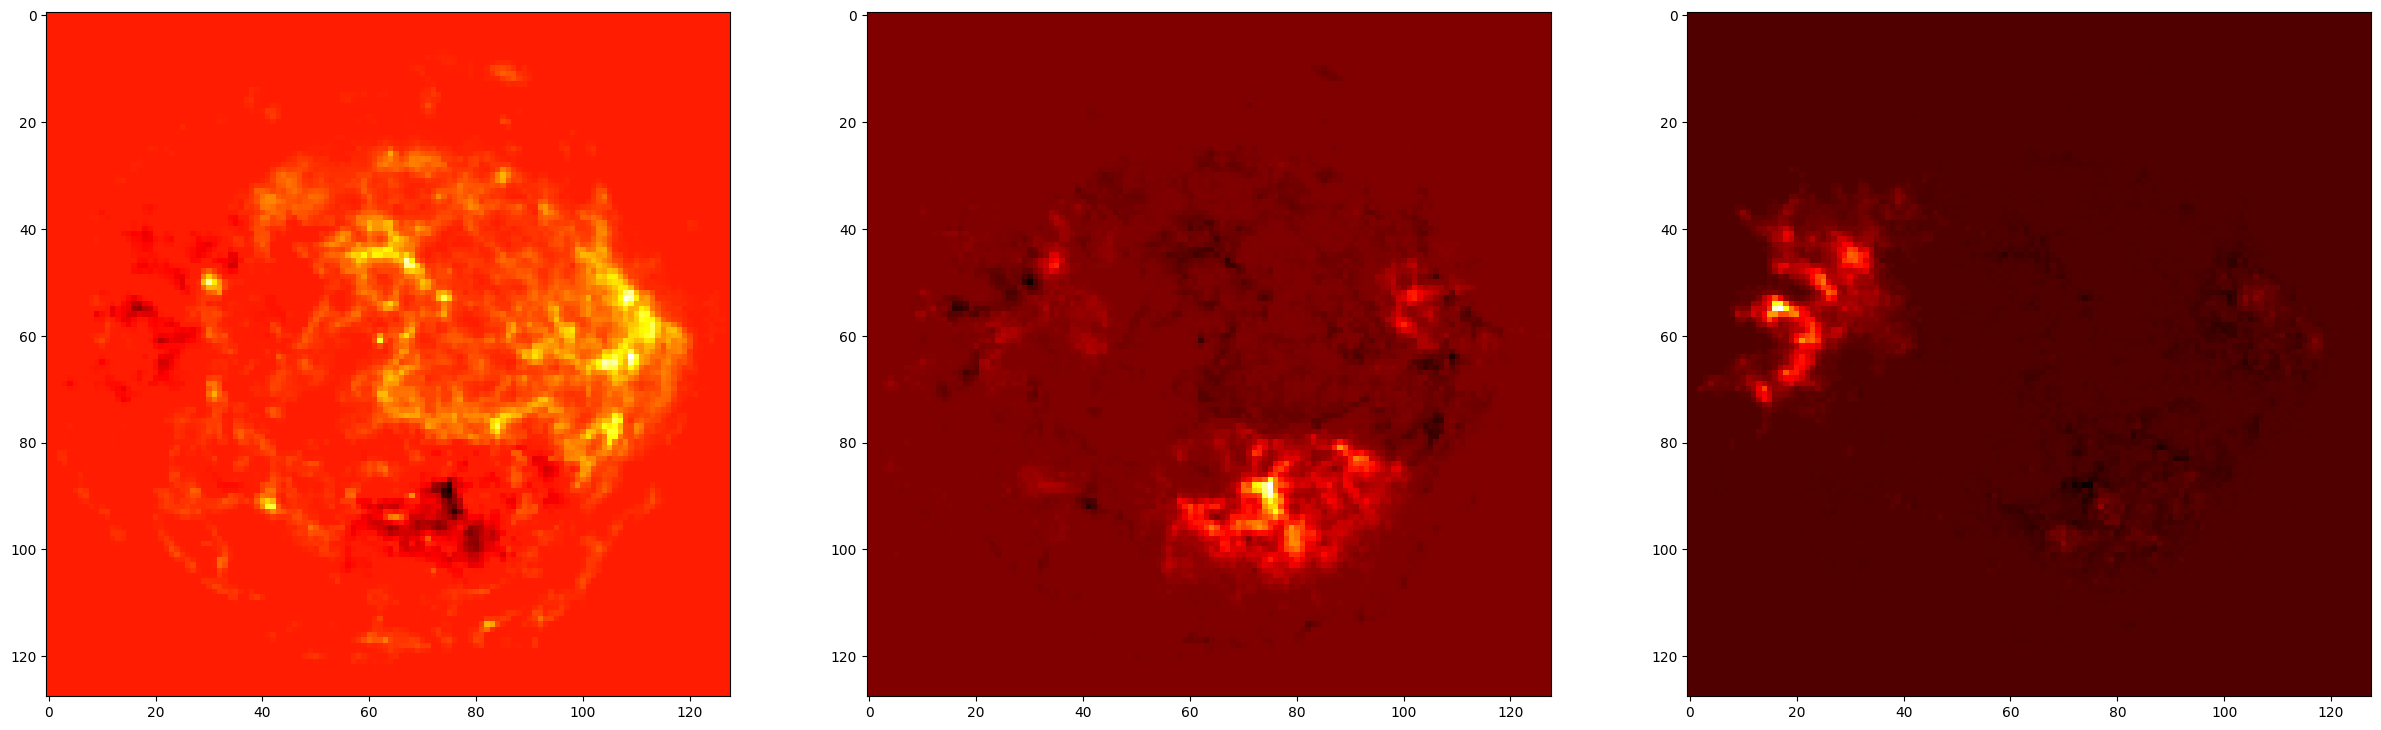

In [11]:
f,ax = plt.subplots(1,3,figsize=(30,15))
for k in range(3):
    ax[k].imshow(S_est.T[k].reshape(128,128),#.transpose(1,2,0),
              cmap='hot')
plt.show()

In [12]:
test = np.array([[1,2],[3,4]])

In [13]:
test.T

array([[1, 3],
       [2, 4]])

In [14]:
A_est,S_est,it

(array([[0.29461477, 0.07302082, 0.14883041],
        [0.28175119, 0.06932883, 0.14372597],
        [0.2738924 , 0.06743486, 0.13759268],
        [0.26191975, 0.06506672, 0.13248847],
        [0.25370152, 0.0613062 , 0.12787022],
        [0.24361473, 0.06015333, 0.12239112],
        [0.23295848, 0.05878946, 0.11842609],
        [0.22515352, 0.05535143, 0.11462001],
        [0.21608602, 0.05382984, 0.11050682],
        [0.21028349, 0.05264456, 0.1057067 ],
        [0.20088962, 0.04926529, 0.10081024],
        [0.19467969, 0.04828864, 0.09799173],
        [0.18649369, 0.04642934, 0.09411089],
        [0.18067367, 0.04446089, 0.09193063],
        [0.17211445, 0.04292495, 0.08651518],
        [0.16631115, 0.04139727, 0.08582157],
        [0.15962345, 0.04012765, 0.08116816],
        [0.15105437, 0.0384768 , 0.08080217],
        [0.14581432, 0.04105227, 0.08181653],
        [0.1360708 , 0.04360065, 0.08967616],
        [0.12293127, 0.05518903, 0.11100352],
        [0.10379542, 0.0759813 , 0